# Webcam Lip-Reading Model Comparison

This notebook runs the **custom-words** isolated-word lip-reading model in `checkpoints/custom_words.pt` against a live webcam clip. The model recognises exactly these 8 words: **hello, hi, yes, no, good, bad, thanks, bye**.

Say **one** of those words, then press **q** to stop recording and classify the captured mouth frames.

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import torch
import torch.nn as nn

from pathlib import Path
import sys

import cv2
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display



def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / 'data' / 'prepare_custom_word_dataset.py').is_file() and (candidate / 'models').is_dir():
            return candidate
    raise FileNotFoundError(
        'Could not find the VisionSpeak project root containing data/prepare_custom_word_dataset.py.'
    )


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from models.valente.model import LipNet, ctc_greedy_decode, tokens_to_text
from models.LBY.model import LipReadingClassifier
from processing.preprocessor import Preprocessor
from processing.video_loader import VideoLoader

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Project root: {PROJECT_ROOT}')
print(f'Device: {device}')

Project root: C:\Users\Valente\OneDrive\Documents\NUS\Pattern Recognition System\Practice Module\VisionSpeak
Device: cuda


In [2]:
CHECKPOINT_PATH = PROJECT_ROOT / 'checkpoints' / 'custom_words.pt'
checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
label_to_index = checkpoint['label_to_index']
index_to_label = {index: word for word, index in label_to_index.items()}

lby_model = LipReadingClassifier(num_classes=len(label_to_index)).to(device)
lby_model.load_state_dict(checkpoint['model_state_dict'])
lby_model.eval()

print(f'Loaded checkpoint: {CHECKPOINT_PATH.name} (epoch {checkpoint["epoch"]})')
print(f'Vocabulary ({len(index_to_label)} words): {sorted(index_to_label.values())}')

Loaded checkpoint: custom_words.pt (epoch 43)
Vocabulary (8 words): ['bad', 'bye', 'good', 'hello', 'hi', 'no', 'thanks', 'yes']


In [3]:
CTC_BLANK = 0
CHECKPOINT_PATH = PROJECT_ROOT / 'checkpoints' / 'valente_custom_words_lipnet_ctc_0.743_acc.pt'
checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
char_to_index = checkpoint['char_to_index']
index_to_char = {index: char for char, index in char_to_index.items()}

valente_model = LipNet(num_classes=len(char_to_index) + 1, input_channels=1).to(device)
valente_model.load_state_dict(checkpoint['model_state_dict'])
valente_model.eval()

print(f'Loaded checkpoint: {CHECKPOINT_PATH.name} (epoch {checkpoint["epoch"]})')
print(f'Vocabulary ({len(index_to_label)} words): {sorted(index_to_label.values())}')

Loaded checkpoint: valente_custom_words_lipnet_ctc_0.743_acc.pt (epoch 171)
Vocabulary (8 words): ['bad', 'bye', 'good', 'hello', 'hi', 'no', 'thanks', 'yes']


In [4]:
# valente : probably need to figure out if there is any difference between the two preparing methods. they look the same
def prepare_custom_frames(frames: np.ndarray) -> torch.Tensor:
    """Match training preprocessing: /255 then per-clip standardisation."""
    tensor = torch.from_numpy(np.asarray(frames, dtype=np.float32)) / 255.0
    tensor = (tensor - tensor.mean()) / (tensor.std() + 1e-6)
    return tensor.unsqueeze(1).unsqueeze(0)  # (1, T, 1, H, W)

def prepare_webcam_clip(frames, max_frames):
    if len(frames) == 0:
        raise ValueError('No webcam frames were captured.')
    if len(frames) > max_frames:
        indices = np.linspace(0, len(frames) - 1, max_frames).round().astype(int)
        frames = frames[indices]

    length = len(frames)
    real_frames = frames.astype(np.float32) / 255.0
    real_frames = (real_frames - real_frames.mean()) / (real_frames.std() + 1e-6)
    padded_frames = np.zeros((max_frames, *real_frames.shape[1:]), dtype=np.float32)
    padded_frames[:length] = real_frames
    tensor = torch.from_numpy(padded_frames).unsqueeze(0).unsqueeze(2).to(device)
    return tensor, torch.tensor([length], dtype=torch.long)

## Record one word

Run the next cell. An OpenCV preview opens with the full webcam view and a green box around the mouth crop. Say **one** of the 8 words, then press **q**. The window closes automatically.

In [6]:
captured_frames = None
video_data = None

try:
    print('Say one word, then press q to stop and predict.')
    video_data = VideoLoader().load('webcam', show_full_frame=True)
    if not video_data.get('loaded'):
        raise ValueError('No webcam frames were captured. Please try again.')

    video_data = Preprocessor().convert_to_greyscale(video_data)
    captured_frames = np.asarray(video_data['frames'], dtype=np.uint8)
    print(f'Captured {len(captured_frames)} mouth-crop frames.')
finally:
    if video_data is not None:
        capture = video_data.get('capture')
        if capture is not None:
            capture.release()
    cv2.destroyAllWindows()

Say one word, then press q to stop and predict.
Captured 142 mouth-crop frames.


## Predict the word

Reports the winner and the three most likely words.

In [ ]:
if captured_frames is None:
    raise RuntimeError('Run the webcam capture cell before running prediction.')

model_input = prepare_custom_frames(captured_frames).to(device)
tensor_input, input_length = prepare_webcam_clip(captured_frames, max_frames=90)

with torch.inference_mode():
    probabilities = torch.softmax(lby_model(model_input), dim=1).squeeze(0).cpu()

top_count = min(3, len(index_to_label))
top_probabilities, top_indices = torch.topk(probabilities, k=top_count)
top_predictions = [
    (index_to_label[int(index)], float(probability))
    for probability, index in zip(top_probabilities, top_indices)
]
predicted_word, confidence = top_predictions[0]

display(Markdown(f'## Prediction: **{predicted_word}** ({confidence:.1%})'))
for rank, (word, probability) in enumerate(top_predictions, start=1):
    print(f'{rank}. {word}: {probability:.1%}')
print("-"*20)

with torch.no_grad():
    webcam_log_probs, webcam_output_lengths = valente_model.ctc_log_probs(tensor_input, input_length)
webcam_tokens = ctc_greedy_decode(webcam_log_probs.cpu(), webcam_output_lengths.cpu(), CTC_BLANK)[0]
webcam_prediction = tokens_to_text(webcam_tokens, index_to_char)
print(f'Captured frames: {len(captured_frames)}')
print(f'Prediction: {webcam_prediction}')

## Prediction: **good** (51.3%)

1. good: 51.3%
2. hello: 28.5%
3. no: 18.6%
--------------------
Captured frames: 104
Prediction: yes


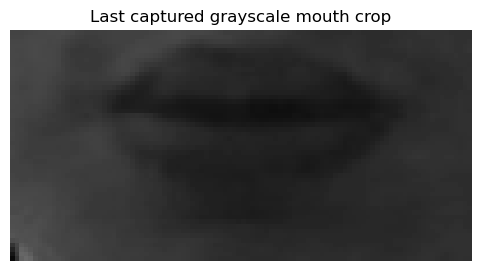

For best results, record only one word with minimal silence before or after it.


In [ ]:
if captured_frames is None:
    raise RuntimeError('Run the webcam capture cell before inspecting frames.')

plt.figure(figsize=(6, 3))
plt.imshow(captured_frames[-1], cmap='gray', vmin=0, vmax=255)
plt.title('Last captured grayscale mouth crop')
plt.axis('off')
plt.show()

print('For best results, record only one word with minimal silence before or after it.')

## Notes

- This model recognises only the 8 custom words: **hello, hi, yes, no, good, bad, thanks, bye**.
- The 71.9% accuracy was measured on a stratified split that mixes the two recording speakers, so live accuracy (especially across a new speaker) may be lower.
- The notebook does not save video. Re-run the capture, prediction, and inspection cells for another attempt.
- If no preview opens, make sure the Jupyter kernel has camera permission and is running in a local GUI-capable Python environment.